# Statistical analysis of mouse to mouse variability

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../")
import clones

plt.rcParams['figure.figsize'] = (3, 3)


import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)
    
    exp_folder = '../../experiment/2410_Dan/'

sexes = ['M', 'F']
ct = 'ctr'

col = {'M': 'r', 'F': 'b'}

exp_folder = '../../experiment/2410_Dan/'

exp_data_all = load_object(exp_folder + 'dan_2410_ctr.pkl')
livesize_all = exp_data_all['livesize']

exp_data_M = load_object(exp_folder + 'dan_2410_ctr_M.pkl')
livesize_M = exp_data_M['livesize']

exp_data_F = load_object(exp_folder + 'dan_2410_ctr_F.pkl')
livesize_F = exp_data_F['livesize']



from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] = 7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 7.5  # General font size
rcParams['text.usetex'] = False
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)
/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case

## Statistical tests for sex differences

- Difference in means for M and F mice
- Difference in distribution (KS test)
- Enhancement of even-sizes for M and F mice for basal and suprabasal

In [2]:
# M vs F difference

from scipy.stats import ks_2samp, binomtest, ttest_ind
from scipy.stats import combine_pvalues
import numpy as np


def hist_to_sample(pdf, n_samples):
    hist_values = n_samples*pdf
    bin_values  = np.arange(0, len(hist_values))
    return np.concatenate([np.repeat(bin_values[i], hist_values[i]) for i in range(len(bin_values))])

def even_sizes_hypothesis_test(data, alpha=0.05, inc0=True, verbose=False):
    # Calculate the observed proportion of even-sized values
    proportion_even = np.mean(data % 2 == 0)
    
    # Calculate the expected proportion of even-sized values assuming a geometric distribution
    if inc0:
        expected_proportion_even = 1 / (1 + np.floor(np.mean(data) / 2))
    else:
        expected_proportion_even = (np.mean(data) - 1)/(2*(np.mean(data)) - 1)
    
    # Perform the one-sample proportion test
    result = binomtest(k=np.sum(data % 2 == 0), n=len(data), p=expected_proportion_even, alternative='greater')
    
    if verbose:
        p_value = result.pvalue
        if p_value < alpha:
            print("Reject the null hypothesis (H0): The observed proportion differs significantly from the expected proportion.")
        else:
            print("Do not reject the null hypothesis (H0): The observed proportion does not significantly differ from the expected proportion.")
        
    return proportion_even, expected_proportion_even, result.pvalue


cpdf = exp_data_all['ctrpdf']
ks_pval = np.zeros((cpdf.shape[0], 2))
t_test_pval = np.zeros((cpdf.shape[0], 2))

M_ev_pval = np.zeros((cpdf.shape[0], 2))
F_ev_pval = np.zeros((cpdf.shape[0], 2))
M_expected_prop = np.zeros((cpdf.shape[0], 2))
F_expected_prop = np.zeros((cpdf.shape[0], 2))
prop_comparison_pval = np.zeros((cpdf.shape[0], 2))

for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        
        # KS test for distribution differences
        statistic, p_value = ks_2samp(sample1, sample2)
        ks_pval[t,l] = p_value
        
        # One-sided t-test for difference in means (H1: Females > Males)
        t_stat, p_value = ttest_ind(sample2, sample1, equal_var=False, alternative='greater')
        t_test_pval[t,l] = p_value
        
        # Even bias tests
        _, M_expected, M_pval = even_sizes_hypothesis_test(sample1, inc0=(l != 0), verbose=False)
        _, F_expected, F_pval = even_sizes_hypothesis_test(sample2, inc0=(l != 0), verbose=False)
        
        M_ev_pval[t,l] = M_pval
        F_ev_pval[t,l] = F_pval
        M_expected_prop[t,l] = M_expected
        F_expected_prop[t,l] = F_expected
        
        # Test if F_expected > M_expected (one-sided)
        # For this comparison, we'll use a bootstrap or permutation test
        # since we're comparing expected proportions
        n_bootstrap = 10000
        diff_observed = F_expected - M_expected
        
        # Create combined sample for permutation
        combined = np.concatenate([sample1, sample2])
        n1 = len(sample1)
        n2 = len(sample2)
        
        diffs = np.zeros(n_bootstrap)
        
        for i in range(n_bootstrap):
            np.random.shuffle(combined)
            boot_sample1 = combined[:n1]
            boot_sample2 = combined[n1:]
            
            # Calculate expected proportions for bootstrap samples
            if l != 0:
                boot_M_expected = 1 / (1 + np.floor(np.mean(boot_sample1) / 2))
                boot_F_expected = 1 / (1 + np.floor(np.mean(boot_sample2) / 2))
            else:
                boot_M_expected = (np.mean(boot_sample1) - 1)/(2*(np.mean(boot_sample1)) - 1)
                boot_F_expected = (np.mean(boot_sample2) - 1)/(2*(np.mean(boot_sample2)) - 1)
            
            diffs[i] = boot_F_expected - boot_M_expected
        
        # Calculate p-value (proportion of bootstrap differences >= observed difference)
        # For one-sided test: F_expected > M_expected
        prop_comparison_pval[t,l] = np.mean(diffs >= diff_observed)


# Analyze by layer (combining across time points)
tol = 0.05


# Combining p-values by layer (across time)
layers = ["Basal", "Suprabasal"]

even_bias_pvals = np.zeros((2, 2, 8))

print("\nStatistical Tests by layer:")

for l in range(2):
    print(f"\n--- {layers[l]} ---")
    
    # T-test for mean difference (F > M)
    t_layer_pvals = t_test_pval[:, l]
    combined_t_layer = combine_pvalues(t_layer_pvals, method='fisher')[1]
    print(f"One-sided t-test for means (F > M): p-values = {t_layer_pvals}, Combined p = {combined_t_layer:.6f}")
    
    # KS test for distribution difference
    ks_layer_pvals = ks_pval[:, l]
    combined_ks_layer = combine_pvalues(ks_layer_pvals, method='fisher')[1]
    print(f"KS test for distributions: p-values = {ks_layer_pvals}, Combined p = {combined_ks_layer:.6f}")
    
    # Even bias test M
    M_ev_layer_pvals = M_ev_pval[:, l]
    combined_M_ev_layer = combine_pvalues(M_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test M: p-values = {M_ev_layer_pvals}, Combined p = {combined_M_ev_layer:.6f}")
    
    # Even bias test F
    F_ev_layer_pvals = F_ev_pval[:, l]
    combined_F_ev_layer = combine_pvalues(F_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test F: p-values = {F_ev_layer_pvals}, Combined p = {combined_F_ev_layer:.6f}")
    
    # Expected proportion comparison (F > M)
    prop_comp_layer_pvals = prop_comparison_pval[:, l]
    combined_prop_comp_layer = combine_pvalues(prop_comp_layer_pvals, method='fisher')[1]
    print(f"Expected proportion comparison (F > M): p-values = {prop_comp_layer_pvals}, Combined p = {combined_prop_comp_layer:.6f}")

# Print statistics on means for context
print("Mean comparison statistics:")
for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        mean1 = np.mean(sample1)  # Male mean
        mean2 = np.mean(sample2)  # Female mean
        print(f"Time {t}, Layer {l}: M mean = {mean1:.3f}, F mean = {mean2:.3f}, Diff (F-M) = {mean2-mean1:.3f}")

# Expected proportion comparison
print("\nExpected proportion of even-sized values comparison (F > M):")
for t in range(cpdf.shape[0]):
    for l in range(2):
        print(f"Time {t}, Layer {layers[l]}: M expected = {M_expected_prop[t,l]:.3f}, F expected = {F_expected_prop[t,l]:.3f}, " +
              f"Diff (F-M) = {F_expected_prop[t,l] - M_expected_prop[t,l]:.3f}, p-value = {prop_comparison_pval[t,l]:.6f}")



Statistical Tests by layer:

--- Basal ---
One-sided t-test for means (F > M): p-values = [6.84019952e-01 3.15129283e-04 1.07149825e-01 8.54657426e-03
 4.85045053e-06 5.24789855e-07 7.64631120e-02 2.39456891e-04], Combined p = 0.000000
KS test for distributions: p-values = [9.04487513e-01 1.35799497e-02 4.02781399e-01 2.83809134e-03
 1.56174821e-05 1.49429297e-05 1.96340339e-01 4.97235062e-02], Combined p = 0.000000
Even bias test M: p-values = [2.09728586e-20 1.37761063e-20 1.17533976e-07 6.73408632e-12
 8.81985699e-03 9.11856594e-06 5.13204695e-03 5.71241723e-02], Combined p = 0.000000
Even bias test F: p-values = [9.35449842e-29 2.07449125e-70 9.04658140e-59 2.89850412e-47
 9.27260788e-39 2.57165199e-37 2.82043348e-35 4.84758603e-10], Combined p = 0.000000
Expected proportion comparison (F > M): p-values = [7.003e-01 7.000e-04 1.230e-01 8.200e-03 0.000e+00 0.000e+00 8.270e-02
 1.000e-03], Combined p = 0.000000

--- Suprabasal ---
One-sided t-test for means (F > M): p-values = [3.69

/home/joelh/Documents/Science/Projects/GlassyTissue/glassy-tissue-turnover/.venv/lib/python3.12/site-packages/scipy/stats/_stats_py.py:9324: RuntimeWarning: divide by zero encountered in log
  statistic = -2 * np.sum(np.log(pvalues))


In [3]:
even_bias_df = pd.DataFrame()
times = exp_data_all['ctrTimeClonesize']
# Add timepoint column
even_bias_df['Timepoint'] = times

# Add p-values for each gender and layer
even_bias_df['Male basal'] = M_ev_pval[:, 0]
even_bias_df['Female basal'] = F_ev_pval[:, 0]
even_bias_df['Male suprabasal'] = M_ev_pval[:, 1]
even_bias_df['Female suprabasal'] = F_ev_pval[:, 1]

# Set the timepoint column as the index
even_bias_df.set_index('Timepoint', inplace=True)

# Transpose the dataframe so timepoints become columns
transposed_df = even_bias_df.transpose()

# Define a function to format floats to 3 significant figures
def sig_fig_formatter(x):
    if isinstance(x, (int, float)):
        return '{:.2g}'.format(x)
    return x

# Generate the LaTeX table with 3 significant figures
latex_table = transposed_df.to_latex(float_format=sig_fig_formatter)

# Display the LaTeX table
print(latex_table)


\begin{tabular}{lrrrrrrrr}
\toprule
Timepoint & 7.000000 & 14.000000 & 21.000000 & 28.000000 & 42.000000 & 56.000000 & 84.000000 & 140.000000 \\
\midrule
Male basal & 2.1e-20 & 1.4e-20 & 1.2e-07 & 6.7e-12 & 0.0088 & 9.1e-06 & 0.0051 & 0.057 \\
Female basal & 9.4e-29 & 2.1e-70 & 9e-59 & 2.9e-47 & 9.3e-39 & 2.6e-37 & 2.8e-35 & 4.8e-10 \\
Male suprabasal & 1 & 1 & 1 & 1 & 1 & 1 & 0.58 & 0.15 \\
Female suprabasal & 1 & 1 & 1 & 5.4e-28 & 3.8e-21 & 9.1e-24 & 1.1e-25 & 0.00094 \\
\bottomrule
\end{tabular}



In [4]:
'''  
    Statistical test for frequency
'''


ca_M = clones.lanalysis(livesize_M, tvals = times, verbose = False, containsBasal = True).add_timezero(0)
ca_F = clones.lanalysis(livesize_F, tvals = times, verbose = False, containsBasal = True).add_timezero(0)


# Statistical tests for mouse-to-mouse variability

Clonal trajectories allow us to design new tests for whether mice follow common dynamics. 

Can the observed differences be explained by the finite sampling, or are there intrinsic/extrinsic differences?

In particular, we ask:
- **By sex:** Can male and female mice, be explained by finite sampling of trajectories from pooled mice?
- **By mouse:** Can we account for mouse-by-mouse differences by sampling stochastic trajectories?

In [5]:
# By sex difference

''' 
    Test for combined basal and suprabasal clones by sex
'''

import scipy.stats as stats

print('Testing whether average clonal dynamics by sex is consistent  with pooled mice for transitions')

times = exp_data_all['ctrTimeClonesize']
times = np.hstack([[0],times])

ca_all = clones.lanalysis(livesize_all, tvals = times, verbose = False).add_timezero(0)

numtoboot = 1000000

livesize_M = exp_data_M['livesize']
livesize_F = exp_data_F['livesize']

ca_M = clones.lanalysis(livesize_M, tvals = times, verbose = False, containsBasal = True).add_timezero(0)
ca_F = clones.lanalysis(livesize_F, tvals = times, verbose = False, containsBasal = True).add_timezero(0)

livesize_by_category = {'M': ca_M.livesize, 'F': ca_F.livesize}
categories = list(livesize_by_category.keys())


for cat in ['M', 'F']:
    se = 0
    se_bas = np.zeros(ca_F.ntimes - 1)
    se_sup = np.zeros(ca_F.ntimes - 1)
    se_ext = np.zeros(ca_F.ntimes - 1)

    ca_x = clones.lanalysis(livesize_by_category[cat], tvals = times, verbose = False, containsBasal = True)
    nsamples = ca_x.nsamples

    nvalid = 0

    for t in range(len(times) - 2):
        #print(t)
        ls_t = [livesize_by_category[s][:,t:(t+2),:]  for s in categories]
        ix_t =  [np.where(ls[:,0,0] > 0)[0] for ls in ls_t]
        ar_t  = [ls[(ls[:,0,0] > 0) & (ls[:,0,1] >= 0),:,:] for ls in ls_t]
        ls_all = np.vstack(ar_t)

        weights = np.hstack([np.ones(idx.shape[0])/idx.shape[0] for idx in ix_t])
        weights /= np.sum(weights)
        idx = np.random.choice(len(ls_all), size = (nsamples[t],numtoboot), replace=True, p = weights)

        bas = ls_all[:,0,0]
        sup = ls_all[:,0,1]
        sub = (bas > 0) & (sup >= 0)
        bas = bas[sub]
        sup = sup[sub]

        
        sub_sample = (np.abs(np.mean(bas[idx],0) - ca_x.av_bas_cs[t]) <= 2/nsamples[t]) & (np.abs(np.mean(sup[idx],0) - ca_x.av_sup_cs[t]) <= 2/nsamples[t]) 
        if np.sum(sub_sample) < 20:
            print('Not enough samples')
            continue
        else:
            nvalid += 3
        #assert(np.sum(sub_sample) >= 20)

        subidx = idx[:,sub_sample]

        next_bas = ls_all[subidx,1,0]
        next_sup = ls_all[subidx,1,1]

        bas_samples = np.array([np.mean(tt[tt > 0]) for tt in next_bas.T])
        sup_samples = np.array([np.mean(tt[tt >= 0]) for tt in next_sup.T])
        ext_samples = np.sum(next_bas == 0, 0)/np.sum(next_bas >= 0, 0)

        se_bas[t] = (ca_x.av_bas_cs[t+1] - np.mean(bas_samples))**2/(np.std(bas_samples)**2 + 1e-10) 
        se_sup[t] = (ca_x.av_sup_cs[t+1] - np.mean(sup_samples))**2/(np.std(sup_samples)**2 + 1e-10)
        dext = (ca_x.pers[t] - ca_x.pers[t+1])/ca_x.pers[t]
        se_ext[t] = (dext - np.mean(ext_samples))**2/(np.std(ext_samples)**2 + 1e-10)

    sse = np.sum(se_bas + se_sup + se_ext)
    p = 1 - stats.chi2.cdf(sse, 3*nvalid)
    print(f'{cat}, p-value: {p}')   

Testing whether average clonal dynamics by sex is consistent  with pooled mice for transitions
M, p-value: 0.9999999615518703
Not enough samples
Not enough samples
Not enough samples
Not enough samples
F, p-value: 1.0364363920545294e-05


Testing whether average clonal dynamics by mice is explained by pooling by sex
M


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)
/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case

Clonal distance, p =  0.004
KS distance, p =  0.023
F


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)


Clonal distance, p =  0.001
KS distance, p =  0.005


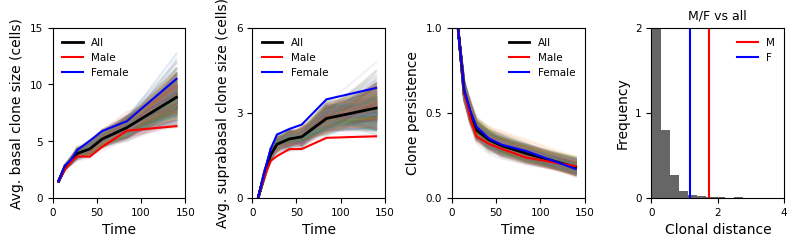

In [6]:
''' 
    Test for combined basal and suprabasal clones by mouse
'''

from importlib import reload
reload(clones)

numtoboot = 1000

p = 2

print('Testing whether average clonal dynamics by mice is explained by pooling by sex')

times = exp_data_all['ctrTimeClonesize']
exp_data_all = load_object(exp_folder + 'dan_2410_ctr.pkl')
livesize_all = exp_data_all['livesize']

fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']

submice = {'M': mmice, 'F': fmice}

label = {'M': 'Male', 'F': 'Female'}

col = {'M': 'r', 'F': 'b'}

plt.figure(figsize = (8, 2.5))

exp_data_M = load_object(exp_folder + 'dan_2410_ctr_M.pkl')
exp_data_F = load_object(exp_folder + 'dan_2410_ctr_F.pkl')
livesize_M = exp_data_M['livesize']
livesize_F = exp_data_F['livesize']

# equally weight even though female has slightly more clones
livesize_all = np.vstack([livesize_M, livesize_F])
weights = np.hstack([np.ones(livesize_M.shape[0])/livesize_M.shape[0], np.ones(livesize_F.shape[0])/livesize_F.shape[0]])
weights = weights[livesize_all[:,0,0] > 0]
weights /= np.sum(weights)
livesize_all = livesize_all[livesize_all[:,0,0] > 0]


ls_rest = livesize_all
ls_rest = ls_rest[np.random.choice(ls_rest.shape[0], size = 10000, p = weights, replace = True),:,:]
ca_rest = clones.lanalysis(ls_rest, tvals = times, verbose = False, containsBasal = True)#.add_timezero(0)
ls_rest = ca_rest.livesize

p_all = {}


for cat in ['M', 'F']:
    print(cat)
    exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + cat + '.pkl')
    livesize = exp_data['livesize']
    times = exp_data['ctrTimeClonesize']
    ca_x = clones.lanalysis(livesize, tvals = times, verbose = False, containsBasal = True)#.add_timezero(0)
    nsamples = ca_x.nsamples

    
    diff_boots = np.zeros(numtoboot)
    ksd_boots = np.zeros(numtoboot)

    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.se_pers**p))
    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p)
    #diff_x = np.sum(np.abs(ca_rest.dbas - ca_x.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_x.dsup)**p)
    diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    ksd_x = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_x.bas_cdf(100))), np.max(np.abs(ca_rest.sup_cdf(100) - ca_x.sup_cdf(100)))])# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    nclones = livesize.shape[0]
    bas_boot = []
    sup_boot = []
    ext_boot = []

    for b in range(numtoboot):
        lsb = ls_rest[np.random.choice(ls_rest.shape[0], size = nclones),:,:]
        ca_b = clones.lanalysis(lsb, tvals = times, verbose = False, containsBasal = True)
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.se_pers**p))
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p)
        #diff_boots[b] = np.sum(np.abs(ca_rest.dbas - ca_b.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_b.dsup)**p)
        diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))  
        ksd_boots[b] = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_b.bas_cdf(100))), np.max(np.abs(ca_rest.sup_cdf(100) - ca_b.sup_cdf(100)))])# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))        

        bas_boot.append(ca_b.av_bas_cs)
        sup_boot.append(ca_b.av_sup_cs)
        ext_boot.append(ca_b.pers)
    bas_boot = np.array(bas_boot)
    sup_boot = np.array(sup_boot)
    ext_boot = np.array(ext_boot)

    pval_diff = np.sum(np.abs(diff_boots) >= np.abs(diff_x))/numtoboot
    print('Clonal distance, p = ', pval_diff)
    pval_ksd = np.sum(np.abs(ksd_boots) >= np.abs(ksd_x))/numtoboot
    print('KS distance, p = ', pval_ksd)

    p_all[cat] = {'diff': pval_diff, 'ksd': pval_ksd}


    plt.subplot(1, 4, 4)
    if cat == 'M':
        plt.hist(diff_boots, color = 'k', alpha = 0.6, density=True)
    plt.axvline(diff_x, color = col[cat], label = cat)
    if cat == 'F':
        plt.legend(frameon = False)         
    plt.xlabel('Clonal distance')
    plt.ylabel('Frequency')
    plt.title(f'M/F vs all')
    plt.xlim([0,4])
    plt.ylim([0, 2])
    plt.xticks([0,2,4])
    plt.yticks([0,1,2])


    plt.subplot(1, 4, 1)
    if cat == 'M':
        plt.plot(ca_x.tvals, np.array(bas_boot)[:1000].T, alpha = 0.1)
        plt.plot(ca_rest.tvals, ca_rest.av_bas_cs, 'k-', label = 'All', linewidth = 2)
    plt.plot(ca_x.tvals, ca_x.av_bas_cs, col[cat], label = label[cat])   
    if cat == 'F':
        plt.legend(frameon = False)         
    plt.xlabel('Time')
    plt.ylabel('Avg. basal clone size (cells)')
    plt.ylim([0, 15])
    plt.xticks([0,50,100,150])
    plt.yticks([0,5,10,15])

    plt.subplot(1, 4, 2)
    if cat == 'M':
        plt.plot(ca_x.tvals, np.array(sup_boot)[:1000].T, alpha = 0.1)
        plt.plot(ca_rest.tvals, ca_rest.av_sup_cs, 'k-', label = 'All', linewidth = 2)
    plt.plot(ca_x.tvals, ca_x.av_sup_cs, col[cat], label = label[cat])
    if cat == 'F':
        plt.legend(frameon = False)         
    plt.xlabel('Time')
    plt.ylabel('Avg. suprabasal clone size (cells)')
    plt.xlim([0, 150])
    plt.ylim([0, 6])
    plt.xticks([0,50,100,150])
    plt.yticks([0,3,6])

    plt.subplot(1, 4, 3)
    if cat == 'M':
        plt.plot(ca_x.tvals, np.array(ext_boot)[:1000].T, alpha = 0.1)
        plt.plot(ca_rest.tvals, ca_rest.pers, 'k-', label = 'All', linewidth = 2)
    plt.plot(ca_x.tvals, ca_x.pers, col[cat], label = label[cat])
    if cat == 'F':
        plt.legend(frameon = False)            
    plt.xlabel('Time')
    plt.ylabel('Clone persistence')
    plt.xlim([0, 150])
    plt.ylim([0, 1])
    plt.xticks([0,50,100,150])
    plt.yticks([0,0.5,1])
plt.tight_layout()
plt.savefig('Figures/Fig1_exp_dynamics/dan_2410_ctr_MF_pooled.pdf', dpi = 300)
plt.show()

Testing whether average clonal dynamics by mice is explained by pooling by sex
M30


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)
/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case

Clonal distance, p =  0.013
KS distance, p =  0.003
M1
Clonal distance, p =  0.02
KS distance, p =  0.063
M14
Clonal distance, p =  0.026
KS distance, p =  0.036
M3
Clonal distance, p =  0.038
KS distance, p =  0.096
M1bis
Clonal distance, p =  0.183
KS distance, p =  0.228
F3
Clonal distance, p =  0.004
KS distance, p =  0.0
F4
Clonal distance, p =  0.021
KS distance, p =  0.094
F11
Clonal distance, p =  0.341
KS distance, p =  0.018
F9
Clonal distance, p =  0.0
KS distance, p =  0.008
F10
Clonal distance, p =  0.13
KS distance, p =  0.321


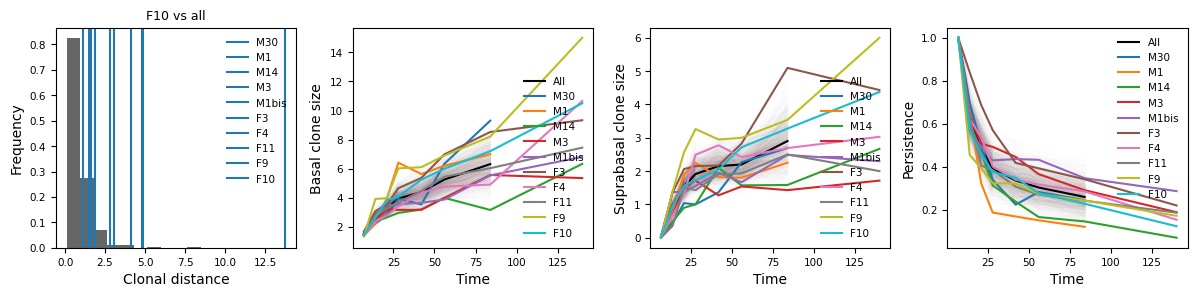

In [7]:
''' 
    Test for combined basal and suprabasal clones by mouse
'''

from importlib import reload
reload(clones)

numtoboot = 1000

p = 2

print('Testing whether average clonal dynamics by mice is explained by pooling by sex')

times = exp_data_all['ctrTimeClonesize']
exp_data_all = load_object(exp_folder + 'dan_2410_ctr.pkl')
livesize_all = exp_data_all['livesize']

fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']

submice = {'M': mmice, 'F': fmice}

col = {'M': 'r', 'F': 'b'}

plt.figure(figsize = (12, 3))

exp_data_M = load_object(exp_folder + 'dan_2410_ctr_M.pkl')
exp_data_F = load_object(exp_folder + 'dan_2410_ctr_F.pkl')
livesize_M = exp_data_M['livesize']
livesize_F = exp_data_F['livesize']

# equally weight even though female has slightly more clones
livesize_all = np.vstack([livesize_M, livesize_F])
weights = np.hstack([np.ones(livesize_M.shape[0])/livesize_M.shape[0], np.ones(livesize_F.shape[0])/livesize_F.shape[0]])
weights = weights[livesize_all[:,0,0] > 0]
weights /= np.sum(weights)
livesize_all = livesize_all[livesize_all[:,0,0] > 0]


ls_rest = livesize_all
ls_rest = ls_rest[np.random.choice(ls_rest.shape[0], size = 10000, p = weights, replace = True),:,:]
ca_rest = clones.lanalysis(ls_rest, tvals = times, verbose = False, containsBasal = True)#.add_timezero(0)
ls_rest = ca_rest.livesize
ca_rest1 = ca_rest.copy()

for cat in mmice + fmice:
    print(cat)
    exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + cat + '.pkl')
    livesize = exp_data['livesize']
    times = exp_data['ctrTimeClonesize']
    ca_x = clones.lanalysis(livesize, tvals = times, verbose = False, containsBasal = True)#.add_timezero(0)
    nsamples = ca_x.nsamples

    ntimes = len(times)
    ca_rest = clones.lanalysis(ca_rest1.live_bas_sb[:,:ntimes,:], tvals = times[:ntimes], verbose = False, containsBasal = True)#.add_timezero(0)
    ls_rest = ca_rest.livesize
    
    diff_boots = np.zeros(numtoboot)
    ksd_boots = np.zeros(numtoboot)

    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.se_pers**p))
    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p)
    #diff_x = np.sum(np.abs(ca_rest.dbas - ca_x.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_x.dsup)**p)
    diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    ksd_x = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_x.bas_cdf(100))), np.max(np.abs(ca_rest.sup_cdf(100) - ca_x.sup_cdf(100)))])# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
    nclones = livesize.shape[0]
    bas_boot = []
    sup_boot = []
    ext_boot = []

    for b in range(numtoboot):
        lsb = ls_rest[np.random.choice(ls_rest.shape[0], size = nclones),:,:]
        ca_b = clones.lanalysis(lsb, tvals = times, verbose = False, containsBasal = True)
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.se_pers**p))
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))
        #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p)
        #diff_boots[b] = np.sum(np.abs(ca_rest.dbas - ca_b.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_b.dsup)**p)
        diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))  
        ksd_boots[b] = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_b.bas_cdf(100))), np.max(np.abs(ca_rest.sup_cdf(100) - ca_b.sup_cdf(100)))])# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))        

        bas_boot.append(ca_b.av_bas_cs)
        sup_boot.append(ca_b.av_sup_cs)
        ext_boot.append(ca_b.pers)
    bas_boot = np.array(bas_boot)
    sup_boot = np.array(sup_boot)
    ext_boot = np.array(ext_boot)
    p_all[cat] = {'diff': pval_diff, 'ksd': pval_ksd}


    pval_diff = np.sum(np.abs(diff_boots) >= np.abs(diff_x))/numtoboot
    print('Clonal distance, p = ', pval_diff)
    pval_ksd = np.sum(np.abs(ksd_boots) >= np.abs(ksd_x))/numtoboot
    print('KS distance, p = ', pval_ksd)


    plt.subplot(1, 4, 1)
    if cat == 'M30':
        plt.hist(diff_boots, color = 'k', alpha = 0.6, density=True)
    plt.axvline(diff_x, label = cat)
    plt.legend(frameon = False)            
    plt.xlabel('Clonal distance')
    plt.ylabel('Frequency')
    plt.title(f'{cat} vs all')

    plt.subplot(1, 4, 2)
    if cat == 'M30':
        plt.plot(ca_x.tvals, np.array(bas_boot).T,  alpha = 0.005)
        plt.plot(ca_rest.tvals, ca_rest.av_bas_cs, 'k-', label = 'All')
    plt.plot(ca_x.tvals, ca_x.av_bas_cs, label = cat)   
    plt.legend(frameon = False)            
    plt.xlabel('Time')
    plt.ylabel('Basal clone size')

    plt.subplot(1, 4, 3)
    if cat == 'M30':
        plt.plot(ca_x.tvals, np.array(sup_boot).T, alpha = 0.005)
        plt.plot(ca_rest.tvals, ca_rest.av_sup_cs, 'k-', label = 'All')
    plt.plot(ca_x.tvals, ca_x.av_sup_cs, label = cat)
    plt.legend(frameon = False)            
    plt.xlabel('Time')
    plt.ylabel('Suprabasal clone size')

    plt.subplot(1, 4, 4)
    if cat == 'M30':
        plt.plot(ca_x.tvals, np.array(ext_boot).T, alpha = 0.005)
        plt.plot(ca_rest.tvals, ca_rest.pers, 'k-', label = 'All')
    plt.plot(ca_x.tvals, ca_x.pers, label = cat)
    plt.legend(frameon = False)            
    plt.xlabel('Time')
    plt.ylabel('Persistence')

plt.tight_layout()
plt.show()

Testing whether average clonal dynamics by mice is explained by pooling by sex
M30


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)


Clonal distance, p =  0.02
KS distance, p =  0.1
Rescaled KS distance, p =  0.22


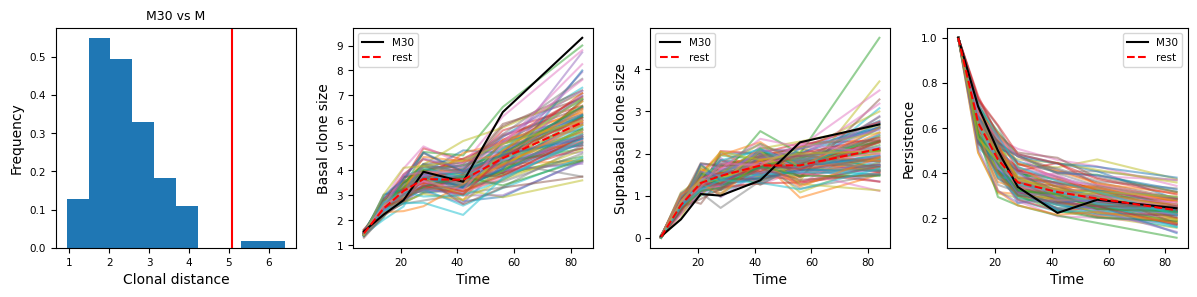

M1
Clonal distance, p =  0.0
KS distance, p =  0.01
Rescaled KS distance, p =  0.75


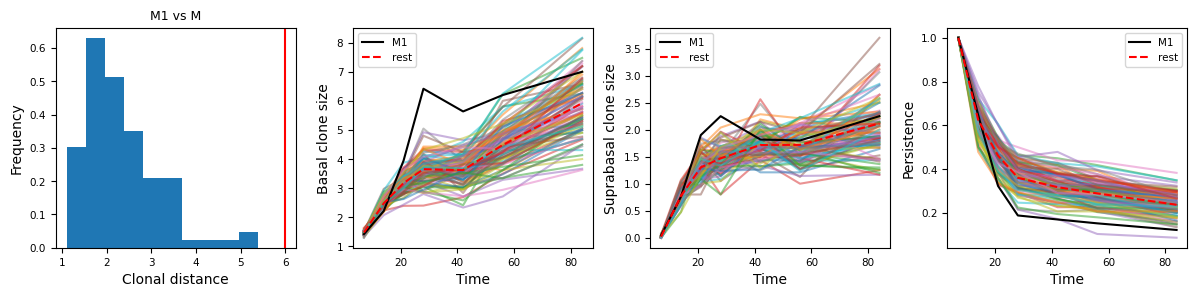

M14
Clonal distance, p =  0.0
KS distance, p =  0.03
Rescaled KS distance, p =  0.04


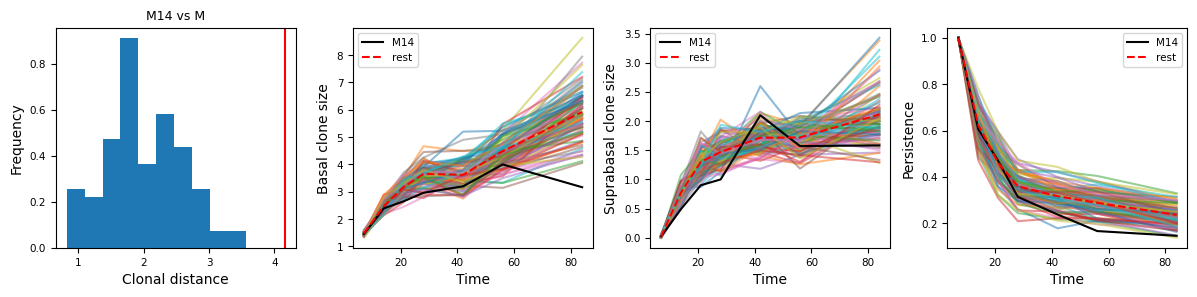

M3
Clonal distance, p =  0.17
KS distance, p =  0.51
Rescaled KS distance, p =  0.43


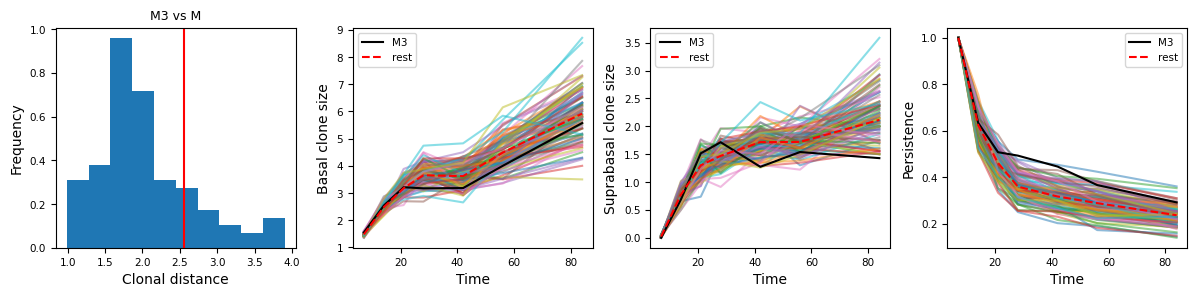

M1bis
Clonal distance, p =  0.25
KS distance, p =  0.12
Rescaled KS distance, p =  0.56


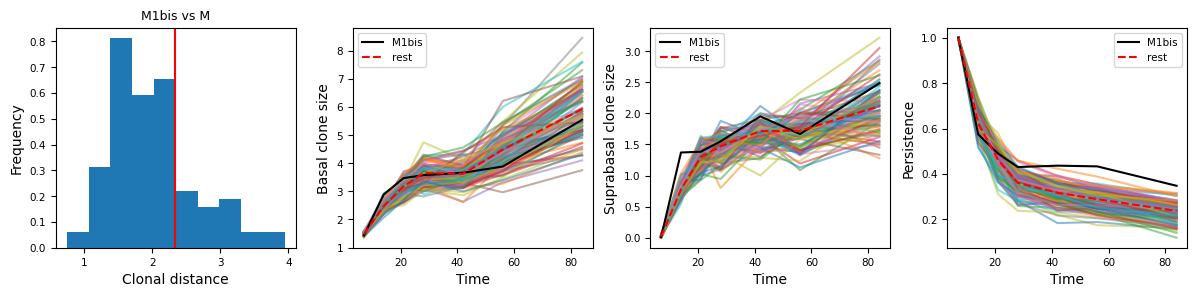

F3
Clonal distance, p =  0.01
KS distance, p =  0.05
Rescaled KS distance, p =  0.31


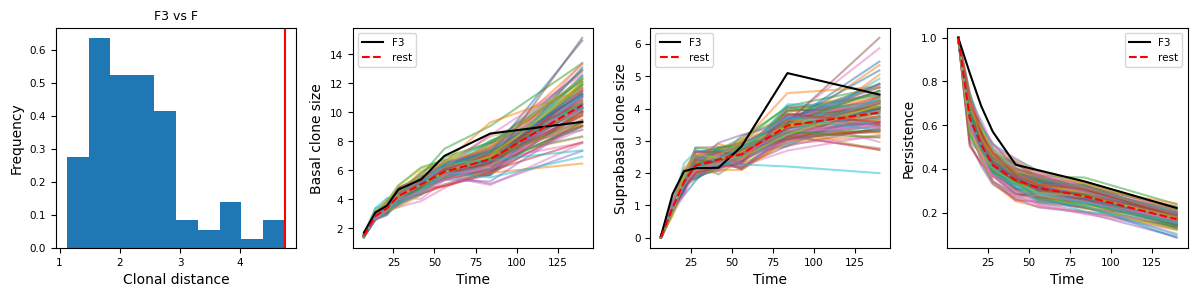

F4
Clonal distance, p =  0.0
KS distance, p =  0.17
Rescaled KS distance, p =  0.16


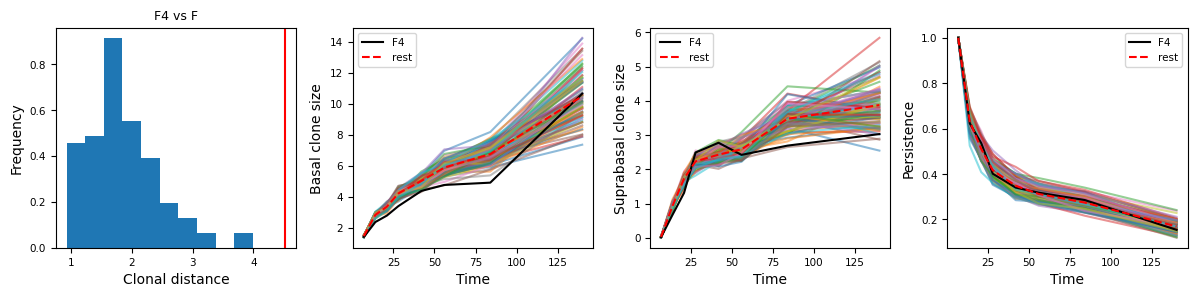

F11
Clonal distance, p =  0.02
KS distance, p =  0.04
Rescaled KS distance, p =  0.43


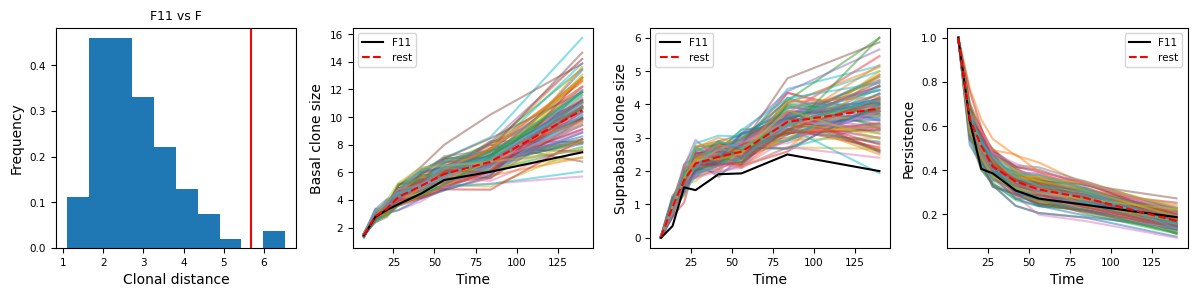

F9
Clonal distance, p =  0.0
KS distance, p =  0.08
Rescaled KS distance, p =  0.88


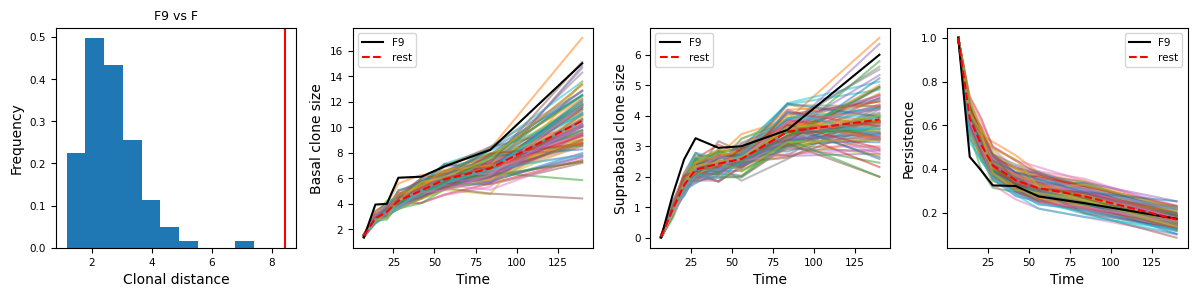

F10
Clonal distance, p =  0.78
KS distance, p =  0.42
Rescaled KS distance, p =  0.65


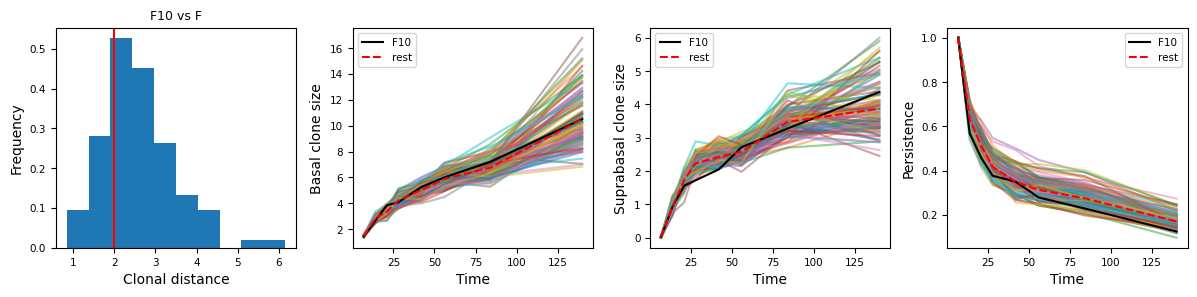

In [8]:
''' 
    Test for combined basal and suprabasal clones by mouse
'''

def rescale_cdf_by_mean(cdf, mean, num_points=1001):
    """
    Rescale a CDF by the mean to compare distribution shapes.
    
    Parameters:
    - cdf: CDF function to be rescaled
    - mean: mean value for rescaling
    - num_points: number of points for interpolation
    
    Returns:
    - x_normalized: normalized x-values (multiples of mean)
    - cdf_values: corresponding CDF values
    """
    # Create normalized x grid (from 0 to 10 times the mean)
    x_normalized = np.linspace(0, 20, num_points)
    
    # Calculate actual sizes by multiplying by mean
    actual_sizes = x_normalized * mean

    actual_sizes[np.ceil(actual_sizes) >= len(cdf)] = len(cdf) - 1
    
    # Calculate CDF values at these actual sizes
    cdf_values = np.array([cdf[np.round(size).astype(int)] for size in actual_sizes])
    
    return x_normalized, cdf_values

def rescaled_ksd(ca1, ca2, max_clone = 100):
    """
    Calculate the Kolmogorov-Smirnov distance between two CDFs.
    
    Parameters:
    - ca1: first clone analysis object
    - ca2: second clone analysis object
    
    Returns:
    - ks_distance: maximum absolute difference between the two CDFs
    """
    ksd = np.zeros((ca1.ntimes, 2))
    for t in range(ca1.ntimes):
        # Rescale CDFs by their means
        x1, cdf1 = rescale_cdf_by_mean(ca1.bas_cdf(max_clone)[t], ca1.av_bas_cs[t])
        x2, cdf2 = rescale_cdf_by_mean(ca2.bas_cdf(max_clone)[t], ca2.av_bas_cs[t])

        # Calculate KS distance between the rescaled CDFs
        ksd[t,0] = np.max(np.abs(cdf1 - cdf2))
        x1, cdf1 = rescale_cdf_by_mean(ca1.sup_cdf(max_clone)[t], ca1.av_sup_cs[t])
        x2, cdf2 = rescale_cdf_by_mean(ca2.sup_cdf(max_clone)[t], ca2.av_sup_cs[t])

        # Calculate KS distance between the rescaled CDFs
        ksd[t,1] = np.max(np.abs(cdf1 - cdf2))
    return ksd

numtoboot = 100

p = 1

print('Testing whether average clonal dynamics by mice is explained by pooling by sex')

times = exp_data_all['ctrTimeClonesize']


fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']

submice = {'M': mmice, 'F': fmice}

for sex in ['M', 'F']:

    nvalid = 0
    for cat in submice[sex]:
        livesize_by_category = {}
        for mid in submice[sex]:
            #if mid == cat:
            #    continue
            exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + mid + '.pkl')
            livesize = exp_data['livesize']
            livesize_by_category[mid] = livesize
        categories = list(livesize_by_category.keys())

        print(cat)
        ntimes = np.min([livesize_by_category[s].shape[1] for s in categories])
        exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + cat + '.pkl')
        livesize = exp_data['livesize'][:,:ntimes,:]
        times = exp_data['ctrTimeClonesize'][:ntimes]
        ca_x = clones.lanalysis(livesize, tvals = times, verbose = False, containsBasal = True)#.add_timezero(0)
        nsamples = ca_x.nsamples
        ls_rest = np.vstack([livesize_by_category[s][:,:ntimes,:] for s in categories])
        ca_rest = clones.lanalysis(ls_rest, tvals = times[:ntimes], verbose = False, containsBasal = True)#.add_timezero(0)
        ls_rest = ca_rest.livesize

        diff_boots = np.zeros(numtoboot)
        ksd_boots = np.zeros(numtoboot)
        resc_ksd_boots = np.zeros(numtoboot)

        #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.se_pers**p))
        #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
        #diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p)
        #diff_x = np.sum(np.abs(ca_rest.dbas - ca_x.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_x.dsup)**p)
        diff_x = np.sum(np.abs(ca_rest.av_bas_cs - ca_x.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_x.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
        ksd_x = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_x.bas_cdf(100)),1), np.max(np.abs(ca_rest.sup_cdf(100) - ca_x.sup_cdf(100)),1)])# + np.sum(np.abs(ca_rest.pers - ca_x.pers)**p/(1e-8+ca_rest.pers**p))
        resc_x = np.sum(rescaled_ksd(ca_rest, ca_x)[3:,:])
        nclones = livesize.shape[0]
        bas_boot = []
        sup_boot = []
        ext_boot = []

        for b in range(numtoboot):
            lsb = ls_rest[np.random.choice(ls_rest.shape[0], size = nclones),:,:]
            ca_b = clones.lanalysis(lsb, tvals = times, verbose = False, containsBasal = True)
            #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.se_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.se_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.se_pers**p))
            #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**p)# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))
            #diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p)
            #diff_boots[b] = np.sum(np.abs(ca_rest.dbas - ca_b.dbas)**p) + np.sum(np.abs(ca_rest.dsup - ca_b.dsup)**p)
            diff_boots[b] = np.sum(np.abs(ca_rest.av_bas_cs - ca_b.av_bas_cs)**p/ca_rest.av_bas_cs**(p/2)) + np.sum(np.abs(ca_rest.av_sup_cs - ca_b.av_sup_cs)**p/ca_rest.av_sup_cs**(p/2))# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))  
            ksd_boots[b] = np.max([np.max(np.abs(ca_rest.bas_cdf(100) - ca_b.bas_cdf(100)),1), np.max(np.abs(ca_rest.sup_cdf(100) - ca_b.sup_cdf(100)),1)])# + np.sum(np.abs(ca_rest.pers - ca_b.pers)**p/(1e-8+ca_rest.pers**p))        
            resc_ksd_boots[b] = np.sum(rescaled_ksd(ca_rest, ca_b)[3:,:])
            bas_boot.append(ca_b.av_bas_cs)
            sup_boot.append(ca_b.av_sup_cs)
            ext_boot.append(ca_b.pers)
        bas_boot = np.array(bas_boot)
        sup_boot = np.array(sup_boot)
        ext_boot = np.array(ext_boot)

        pval_diff = np.sum(np.abs(diff_boots) >= np.abs(diff_x))/numtoboot
        print('Clonal distance, p = ', pval_diff)
        pval_ksd = np.sum(np.abs(ksd_boots) >= np.abs(ksd_x))/numtoboot
        print('KS distance, p = ', pval_ksd)
        pval_resc = np.sum(np.abs(resc_ksd_boots) >= np.abs(resc_x))/numtoboot
        print('Rescaled KS distance, p = ', pval_resc)


        plt.figure(figsize = (12, 3))
        plt.subplot(1, 4, 1)
        plt.hist(diff_boots, density=True)
        plt.axvline(diff_x, color = 'r')
        plt.xlabel('Clonal distance')
        plt.ylabel('Frequency')
        plt.title(f'{cat} vs {sex}')

        plt.subplot(1, 4, 2)
        plt.plot(ca_x.tvals, np.array(bas_boot).T, alpha = 0.5)
        plt.plot(ca_x.tvals, ca_x.av_bas_cs, 'k-', label = cat)   
        plt.plot(ca_rest.tvals, ca_rest.av_bas_cs, 'r--', label = 'rest')
        plt.legend()     
        plt.xlabel('Time')
        plt.ylabel('Basal clone size')

        plt.subplot(1, 4, 3)
        plt.plot(ca_x.tvals, np.array(sup_boot).T, alpha = 0.5)
        plt.plot(ca_x.tvals, ca_x.av_sup_cs, 'k-', label = cat)
        plt.plot(ca_rest.tvals, ca_rest.av_sup_cs, 'r--', label = 'rest')
        plt.legend()            
        plt.xlabel('Time')
        plt.ylabel('Suprabasal clone size')

        plt.subplot(1, 4, 4)
        plt.plot(ca_x.tvals, np.array(ext_boot).T, alpha = 0.5)
        plt.plot(ca_x.tvals, ca_x.pers, 'k-', label = cat)
        plt.plot(ca_rest.tvals, ca_rest.pers, 'r--', label = 'rest')
        plt.legend()            
        plt.xlabel('Time')
        plt.ylabel('Persistence')

        plt.tight_layout()
        plt.show()

Text(0, 0.5, 'CDF')

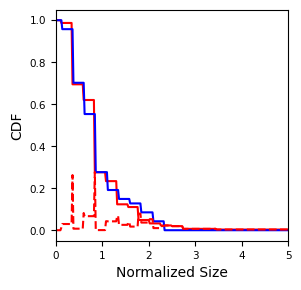

In [9]:
def rescale_cdf_by_mean(cdf, mean, num_points=1001, max_size=20):
    """
    Rescale a CDF by the mean to compare distribution shapes.
    
    Parameters:
    - cdf: CDF function to be rescaled
    - mean: mean value for rescaling
    - num_points: number of points for interpolation
    
    Returns:
    - x_normalized: normalized x-values (multiples of mean)
    - cdf_values: corresponding CDF values
    """
    # Create normalized x grid (from 0 to 10 times the mean)
    x_normalized = np.linspace(0, max_size, num_points)
    
    # Calculate actual sizes by multiplying by mean
    actual_sizes = x_normalized * mean

    actual_sizes[np.ceil(actual_sizes) >= len(cdf)] = len(cdf) - 1
    
    # Calculate CDF values at these actual sizes
    cdf_values = np.array([cdf[np.round(size).astype(int)] for size in actual_sizes])
    
    return x_normalized, cdf_values

def rescaled_ksd(ca1, ca2, max_clone = 100):
    """
    Calculate the Kolmogorov-Smirnov distance between two CDFs.
    
    Parameters:
    - ca1: first clone analysis object
    - ca2: second clone analysis object
    
    Returns:
    - ks_distance: maximum absolute difference between the two CDFs
    """
    ksd = np.zeros((ca1.ntimes, 2))
    for t in range(ca1.ntimes):
        # Rescale CDFs by their means
        x1, cdf1 = rescale_cdf_by_mean(ca1.bas_cdf(max_clone)[t], ca1.av_bas_cs[t])
        x2, cdf2 = rescale_cdf_by_mean(ca2.bas_cdf(max_clone)[t], ca2.av_bas_cs[t])

        # Calculate KS distance between the rescaled CDFs
        ksd[t,0] = np.max(np.abs(cdf1 - cdf2))
        x1, cdf1 = rescale_cdf_by_mean(ca1.sup_cdf(max_clone)[t], ca1.av_sup_cs[t])
        x2, cdf2 = rescale_cdf_by_mean(ca2.sup_cdf(max_clone)[t], ca2.av_sup_cs[t])

        # Calculate KS distance between the rescaled CDFs
        ksd[t,1] = np.max(np.abs(cdf1 - cdf2))
    return ksd


# For your specific case
t = 3  # Time point
x_norm_rest, cdf_rest = rescale_cdf_by_mean(ca_rest.bas_cdf(100)[t], ca_rest.av_bas_cs[t])
x_norm_x, cdf_x = rescale_cdf_by_mean(ca_x.bas_cdf(100)[t], ca_x.av_bas_cs[t])

# Calculate KS distance between the rescaled CDFs
ks_distance = np.max(np.abs(cdf_rest - cdf_x))

plt.plot(x_norm_rest, cdf_rest, label='Rest', color='red')
plt.plot(x_norm_x, cdf_x, label='X', color='blue')
plt.plot(x_norm_rest, (np.abs(cdf_rest - cdf_x)), 'r--', label='Rest')
plt.xlim([0,5])
plt.xlabel('Normalized Size')   
plt.ylabel('CDF')

M


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)


Jensen-Shannon divergence, p =  0.994


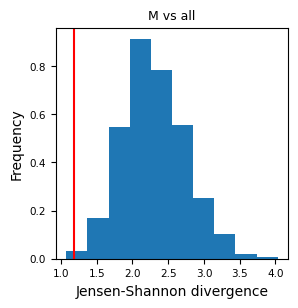

F
Jensen-Shannon divergence, p =  0.016


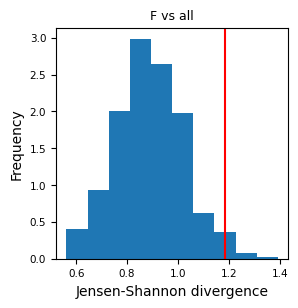

In [10]:
''' 
    Hypothesis testing based on cumulatives of transition probabilities:
'''

import scipy.stats as stats


def move_JSD(f1, f2, min_state):
    ''' 
        Compute the Jensen-Shannon divergence of two transition matrices
            summing over common states that occur at least as frequently
            as min_state
    '''

    norm1 = np.sum(f1, axis = (3,4))
    norm2 = np.sum(f2, axis = (3,4))

    P1 = f1/(norm1 + (norm1 == 0))[:,:,:,None,None]
    P2 = f2/(norm2 + (norm2 == 0))[:,:,:,None,None]

    # Extract states observed at least 15 times 
    top_indices = np.argwhere((norm1 >= min_state) & (norm2 >= min_state))
    totsize = np.sum(top_indices[:,1:],1)
    bassize = top_indices[:,1]
    top_indices = top_indices[bassize > 0,:]

    # Calculate the Jensen-Shannon divergence of the transition probabilities
    JSD = np.zeros(top_indices.shape[0])
    for i in range(top_indices.shape[0]):
        idx = top_indices[i,:]
        Q = (P1[idx[0], idx[1], idx[2], :, :] + P2[idx[0], idx[1], idx[2], :, :])/2
        JSD[i] = (stats.entropy(P1[idx[0], idx[1], idx[2], :, :], Q, axis = (0,1), base = 2) + stats.entropy(P2[idx[0], idx[1], idx[2], :, :], Q, axis = (0,1), base = 2))/2
    return JSD, top_indices


times = exp_data_all['ctrTimeClonesize']
times = np.hstack([[0],times])

ca_M = clones.lanalysis(livesize_M, tvals = times, verbose = False, containsBasal = True).add_timezero(0)
ca_F = clones.lanalysis(livesize_F, tvals = times, verbose = False, containsBasal = True).add_timezero(0)
ca_all = clones.lanalysis(livesize_all, tvals = times, verbose = False).add_timezero(0)

ca_M = clones.lanalysis(livesize_M, tvals = times, verbose = False, containsBasal = False).add_timezero(0)
Mmoves = ca_M.allmoves(max_bas=60, max_sup=30)
Mbas   = ca_M.allmoves_bas(max_bas=60)
Mbas = Mbas/np.sum(Mbas + (Mbas == 0), 1)[:,:,None]

ca_F = clones.lanalysis(livesize_F, tvals = times, verbose = False, containsBasal = False).add_timezero(0)
Fmoves = ca_F.allmoves(max_bas=60, max_sup=30)
Fbas   = ca_F.allmoves_bas(max_bas=60)
Fbas = Fbas/np.sum(Fbas + (Fbas == 0), 1)[:,:,None]


nboots = 500

livesize_all = np.vstack([ca_M.livesize, ca_F.livesize])
ls_weights = np.hstack([np.ones(ca_M.livesize.shape[0])/ca_M.livesize.shape[0], np.ones(ca_F.livesize.shape[0])/ca_F.livesize.shape[0]])
ls_weights /= np.sum(ls_weights)

ftrans_sex = {'M': Mmoves,  'F': Fmoves}
other_sex = {'M': 'F', 'F': 'M'}

k_mjsd = 15


for mid in sexes:
    print(mid)
    exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + mid + '.pkl')

    livesize = exp_data['livesize']

    JSD, top_indices = move_JSD(ftrans_sex[mid], ftrans_sex[other_sex[mid]], k_mjsd)
    JSD = np.sum(JSD)

    nclones = livesize.shape[0]
    
    jsd_boots = np.zeros(nboots)

    for b in range(nboots):
        lsb = livesize_all[np.random.choice(livesize_all.shape[0], size = nclones, p = ls_weights),:,:]
        ca = clones.lanalysis(lsb, tvals = times, verbose = False, containsBasal = False)
        jsdb, top_indices = move_JSD(ca.allmoves(max_bas=60, max_sup=30), ftrans_sex[other_sex[mid]], k_mjsd)
        jsd_boots[b] = np.sum(jsdb)
        
    pval_jsd = np.sum(jsd_boots > JSD)/nboots

    print('Jensen-Shannon divergence, p = ', pval_jsd)

    plt.figure()
    plt.hist(jsd_boots, density=True)
    plt.axvline(JSD, color = 'r')
    plt.xlabel('Jensen-Shannon divergence')
    plt.ylabel('Frequency')
    plt.title(f'{mid} vs all')
    plt.show()

M
Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]] 4
Norms: [57 23 31 18]


/tmp/ipykernel_29010/3069061608.py:19: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  return pickle.load(outp)


Jensen-Shannon divergence, p =  1.0


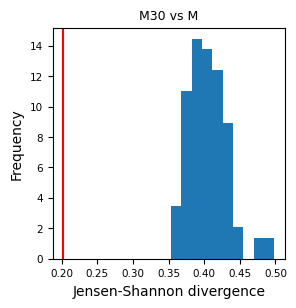

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 1]] 4
Norms: [67 38 24 11]
Jensen-Shannon divergence, p =  1.0


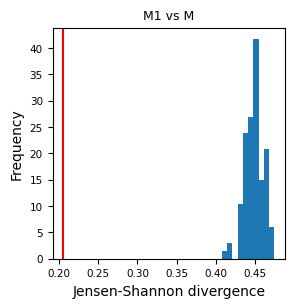

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]
 [2 2 1]
 [3 2 1]
 [4 2 1]] 7
Norms: [86 45 37 17  9 16  8]
Jensen-Shannon divergence, p =  1.0


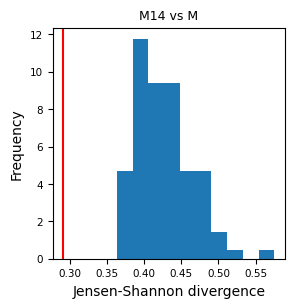

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]
 [2 2 1]
 [4 2 1]] 6
Norms: [76 34 36 10 11  9]
Jensen-Shannon divergence, p =  1.0


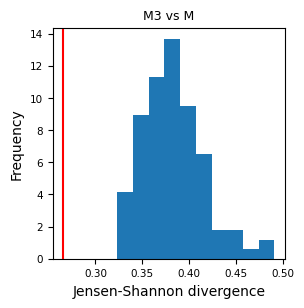

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 1]
 [6 2 1]] 5
Norms: [98 53 39  9  9]
Jensen-Shannon divergence, p =  1.0


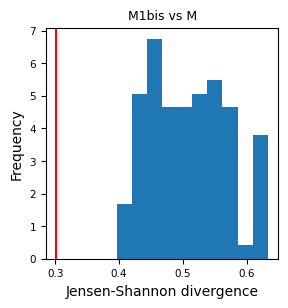

F
Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]
 [2 2 1]
 [2 2 2]
 [2 4 0]
 [2 4 2]
 [3 2 0]
 [3 2 2]
 [3 6 2]
 [4 2 2]
 [4 4 2]
 [5 4 2]
 [5 6 2]] 15
Norms: [149  62  71  17   9  22  14  13   9  25  15   9   8   8   9]
Jensen-Shannon divergence, p =  1.0


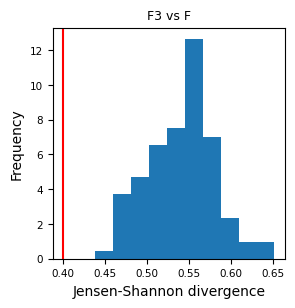

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 1 0]
 [2 2 0]
 [2 2 1]
 [2 2 2]
 [2 3 0]
 [2 4 0]
 [3 2 0]
 [3 2 1]
 [3 2 2]
 [3 2 4]
 [3 4 0]
 [3 4 2]
 [4 2 2]
 [4 4 2]
 [5 2 2]
 [5 4 2]
 [6 6 2]] 20
Norms: [239 151  81  15  36  37  17  10  14  14  29  26   8  14  13  18  15  10
  18  12]
Jensen-Shannon divergence, p =  1.0


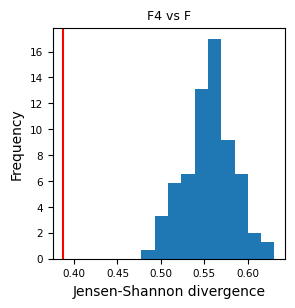

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]
 [2 2 2]
 [2 4 0]
 [3 2 2]
 [3 4 0]
 [4 4 2]] 9
Norms: [109  62  47  21   9  19  10   9  10]
Jensen-Shannon divergence, p =  1.0


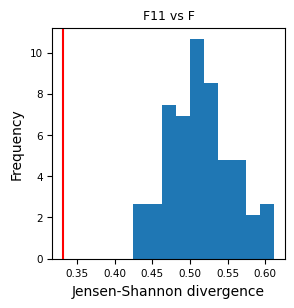

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 1]] 4
Norms: [119  74  37  11]
Jensen-Shannon divergence, p =  1.0


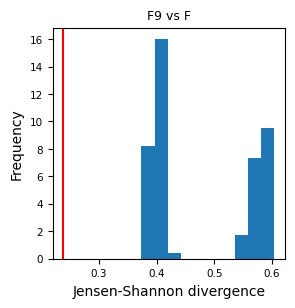

Top indices: [[0 1 0]
 [1 1 0]
 [1 2 0]
 [2 2 0]
 [2 2 1]] 5
Norms: [129  67  56  10  23]
Jensen-Shannon divergence, p =  1.0


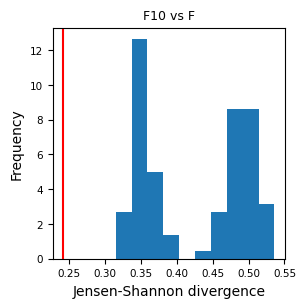

In [11]:
'''
    Hypothesis testing between mice:
        Using Jesnsen Shannon test between joint for the same sex, and individual mice
'''

def move_JSD(f1, f2, min_state, print_top_indices = False, top_indices = None):
    ''' 
        Compute the Jensen-Shannon divergence of two transition matrices
            summing over common states that occur at least as frequently
            as min_state
    '''

    norm1 = np.sum(f1, axis = (3,4))
    norm2 = np.sum(f2, axis = (3,4))

    P1 = f1/(norm1 + (norm1 == 0))[:,:,:,None,None]
    P2 = f2/(norm2 + (norm2 == 0))[:,:,:,None,None]
    
    if top_indices is None:
        # Extract states observed at least 15 times 
        top_indices = np.argwhere((norm1 >= min_state) & (norm2 >= min_state))
        totsize = np.sum(top_indices[:,1:],1)
        bassize = top_indices[:,1]
        top_indices = top_indices[bassize > 0,:]

        if print_top_indices:
            print('Top indices:', top_indices,  f'{top_indices.shape[0]}')
            print('Norms:', norm1[top_indices[:,0], top_indices[:,1], top_indices[:,2]])
            #print('Top indices values:', norm1[top_indices[:,0], top_indices[:,1], top_indices[:,2], :, :])

    # Calculate the Jensen-Shannon divergence of the transition probabilities
    JSD = np.zeros(top_indices.shape[0])
    for i in range(top_indices.shape[0]):
        idx = top_indices[i,:]
        Q = (P1[idx[0], idx[1], idx[2], :, :] + P2[idx[0], idx[1], idx[2], :, :])/2
        JSD[i] = (stats.entropy(P1[idx[0], idx[1], idx[2], :, :], Q, axis = (0,1), base = 2) + stats.entropy(P2[idx[0], idx[1], idx[2], :, :], Q, axis = (0,1), base = 2))/2
    return JSD, top_indices


fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']

ftrans_sex = {'M': Mmoves,  'F': Fmoves}
other_sex = {'M': 'F', 'F': 'M'}
ls_sex = {'M': ca_M.livesize, 'F': ca_F.livesize}
submice = {'M': mmice, 'F': fmice}

nboots = 100

k_mjsd = 8

for sex in sexes:
    print(sex)
    livesize_all = ls_sex[sex]
    

    cvm_mid = np.zeros(len(submice[sex]))
    i = 0
    for mid in submice[sex]:

        exp_data = load_object(exp_folder + 'dan_2410_' + ct + '_' + mid + '.pkl')

        livesize = exp_data['livesize']
        ntimes = livesize.shape[1]
        times = exp_data['ctrTimeClonesize']
        ca = clones.lanalysis(livesize, tvals = times, verbose = False, containsBasal = False).add_timezero(0)
        
        f_mouse = ca.allmoves(max_bas=60, max_sup=30)
        f_sex_rest = ftrans_sex[sex][:ntimes,...] - f_mouse

        JSD, top_indices = move_JSD(f_mouse, f_sex_rest, k_mjsd, print_top_indices = True)
        JSD = np.nanmean(JSD)

        nclones = livesize.shape[0]

        jsd_boots = np.zeros(nboots)

        for b in range(nboots):
            lsb = livesize_all[np.random.choice(livesize_all.shape[0], size = nclones),:ntimes,:]
            ca = clones.lanalysis(lsb, tvals = times, verbose = False, containsBasal = False).add_timezero(0)
            f_mouse = ca.allmoves(max_bas=60, max_sup=30)      
            jsdb, top_indices = move_JSD(f_mouse, f_sex_rest, k_mjsd, False, top_indices)
            jsd_boots[b] = np.nanmean(jsdb)

        i += 1

        pval_jsd = np.sum(jsd_boots > JSD)/nboots

        print('Jensen-Shannon divergence, p = ', pval_jsd)

        plt.figure()
        plt.hist(jsd_boots, density=True)
        plt.axvline(JSD, color = 'r')
        plt.xlabel('Jensen-Shannon divergence')
        plt.ylabel('Frequency')
        plt.title(f'{mid} vs {sex}')
        plt.show()


In [12]:
# By sex difference

''' 
    Test for combined basal and suprabasal clones by sex
'''

import scipy.stats as stats

print('Testing whether average clonal dynamics by sex is consistent  with pooled mice')

times = exp_data_all['ctrTimeClonesize']
times = np.hstack([[0],times])

ca_all = clones.lanalysis(livesize_all, tvals = times, verbose = False).add_timezero(0)

numtoboot = 1000000

livesize_M = exp_data_M['livesize']
livesize_F = exp_data_F['livesize']

ca_M = clones.lanalysis(livesize_M, tvals = times, verbose = False, containsBasal = True).add_timezero(0)
ca_F = clones.lanalysis(livesize_F, tvals = times, verbose = False, containsBasal = True).add_timezero(0)

livesize_by_category = {'M': ca_M.livesize, 'F': ca_F.livesize}
categories = list(livesize_by_category.keys())


for cat in ['M', 'F']:
    se = 0
    se_bas = np.zeros(ca_F.ntimes - 1)
    se_sup = np.zeros(ca_F.ntimes - 1)
    se_ext = np.zeros(ca_F.ntimes - 1)

    ca_x = clones.lanalysis(livesize_by_category[cat], tvals = times, verbose = False, containsBasal = True)
    nsamples = ca_x.nsamples

    nvalid = 0

    for t in range(len(times) - 2):
        #print(t)
        ls_t = [livesize_by_category[s][:,t:(t+2),:]  for s in categories]
        ix_t =  [np.where(ls[:,0,0] > 0)[0] for ls in ls_t]
        ar_t  = [ls[(ls[:,0,0] > 0) & (ls[:,0,1] >= 0),:,:] for ls in ls_t]
        ls_all = np.vstack(ar_t)

        weights = np.hstack([np.ones(idx.shape[0])/idx.shape[0] for idx in ix_t])
        weights /= np.sum(weights)
        idx = np.random.choice(len(ls_all), size = (nsamples[t],numtoboot), replace=True, p = weights)

        bas = ls_all[:,0,0]
        sup = ls_all[:,0,1]
        sub = (bas > 0) & (sup >= 0)
        bas = bas[sub]
        sup = sup[sub]

        
        sub_sample = (np.abs(np.mean(bas[idx],0) - ca_x.av_bas_cs[t]) <= 2/nsamples[t]) & (np.abs(np.mean(sup[idx],0) - ca_x.av_sup_cs[t]) <= 2/nsamples[t]) 
        if np.sum(sub_sample) < 20:
            print('Not enough samples')
            continue
        else:
            nvalid += 3
        #assert(np.sum(sub_sample) >= 20)

        subidx = idx[:,sub_sample]

        next_bas = ls_all[subidx,1,0]
        next_sup = ls_all[subidx,1,1]

        bas_samples = np.array([np.mean(tt[tt > 0]) for tt in next_bas.T])
        sup_samples = np.array([np.mean(tt[tt >= 0]) for tt in next_sup.T])
        ext_samples = np.sum(next_bas == 0, 0)/np.sum(next_bas >= 0, 0)

        se_bas[t] = (ca_x.av_bas_cs[t+1] - np.mean(bas_samples))**2/(np.std(bas_samples)**2 + 1e-10) 
        se_sup[t] = (ca_x.av_sup_cs[t+1] - np.mean(sup_samples))**2/(np.std(sup_samples)**2 + 1e-10)
        dext = (ca_x.pers[t] - ca_x.pers[t+1])/ca_x.pers[t]
        se_ext[t] = (dext - np.mean(ext_samples))**2/(np.std(ext_samples)**2 + 1e-10)

    sse = np.sum(se_bas + se_sup + se_ext)
    p = 1 - stats.chi2.cdf(sse, 3*nvalid)
    print(f'{cat}, p-value: {p}')   

Testing whether average clonal dynamics by sex is consistent  with pooled mice
Not enough samples
M, p-value: 0.9999957554618715
Not enough samples
Not enough samples
Not enough samples
Not enough samples
F, p-value: 3.4622992616251125e-06
